# Wine Quality: Exploratory Data Analysis

Phase 1 binary classification uses the UCI red-wine quality data. The target is `good = 1` when `quality >= 6`; `quality` itself is excluded from model features to prevent target leakage.

## Load data and inspect structure

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "data" / "raw" / "winequality-red.csv").exists()
)
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "winequality-red.csv"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, sep=";")
df["good"] = (df["quality"] >= 6).astype(int)

print(f"Dataset path: {DATA_PATH}")
print(f"Shape (rows, columns): {df.shape}")
print("Data types:")
display(df.dtypes.rename("dtype").to_frame())
print("First five rows:")
display(df.head())
print("Descriptive statistics:")
display(df.describe().T)

Dataset path: C:\Users\naikj\Desktop\Smart-Laboratory-Report-Generator\data\raw\winequality-red.csv
Shape (rows, columns): (1599, 13)
Data types:


,dtype
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


First five rows:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,good
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


## Missing values and duplicate rows

In [2]:
missing_summary = df.isna().sum().rename("missing_values").to_frame()
print("Missing values by column:")
display(missing_summary)
duplicate_count = int(df.duplicated().sum())
print(f"Exact duplicate rows (beyond first occurrence): {duplicate_count}")

Missing values by column:


,missing_values
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Exact duplicate rows (beyond first occurrence): 240


## Target distribution and binary label balance

Quality counts:


,count
quality,
3,10
4,53
5,681
6,638
7,199
8,18


Binary label counts:


,count
good,
Not good (0),744
Good (1),855


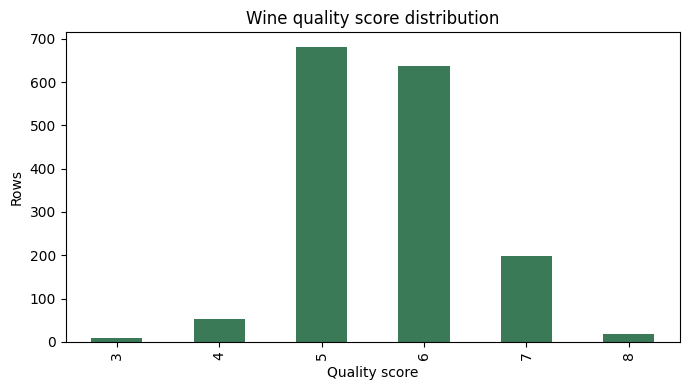

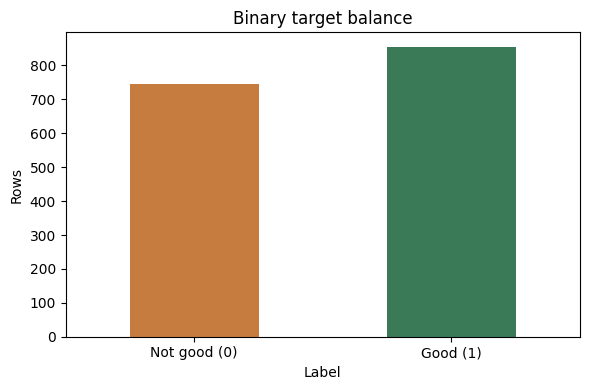

In [3]:
quality_counts = df["quality"].value_counts().sort_index()
label_counts = df["good"].value_counts().sort_index()
label_names = {0: "Not good (0)", 1: "Good (1)"}
print("Quality counts:")
display(quality_counts.rename("count").to_frame())
print("Binary label counts:")
display(label_counts.rename(index=label_names).rename("count").to_frame())

fig, ax = plt.subplots(figsize=(7, 4))
quality_counts.plot(kind="bar", ax=ax, color="#3b7a57")
ax.set(title="Wine quality score distribution", xlabel="Quality score", ylabel="Rows")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "quality_distribution.png", dpi=150, bbox_inches="tight")
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(6, 4))
label_plot_counts = label_counts.rename(index=label_names)
label_plot_counts.plot(kind="bar", ax=ax, color=["#c77c3f", "#3b7a57"])
ax.set(title="Binary target balance", xlabel="Label", ylabel="Rows")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "binary_label_balance.png", dpi=150, bbox_inches="tight")
display(fig)
plt.close(fig)

## Feature distributions and outliers

The plots exclude both `quality` (the source of the label) and the derived `good` label. Each boxplot uses its feature's own scale so outliers remain visible across different units.

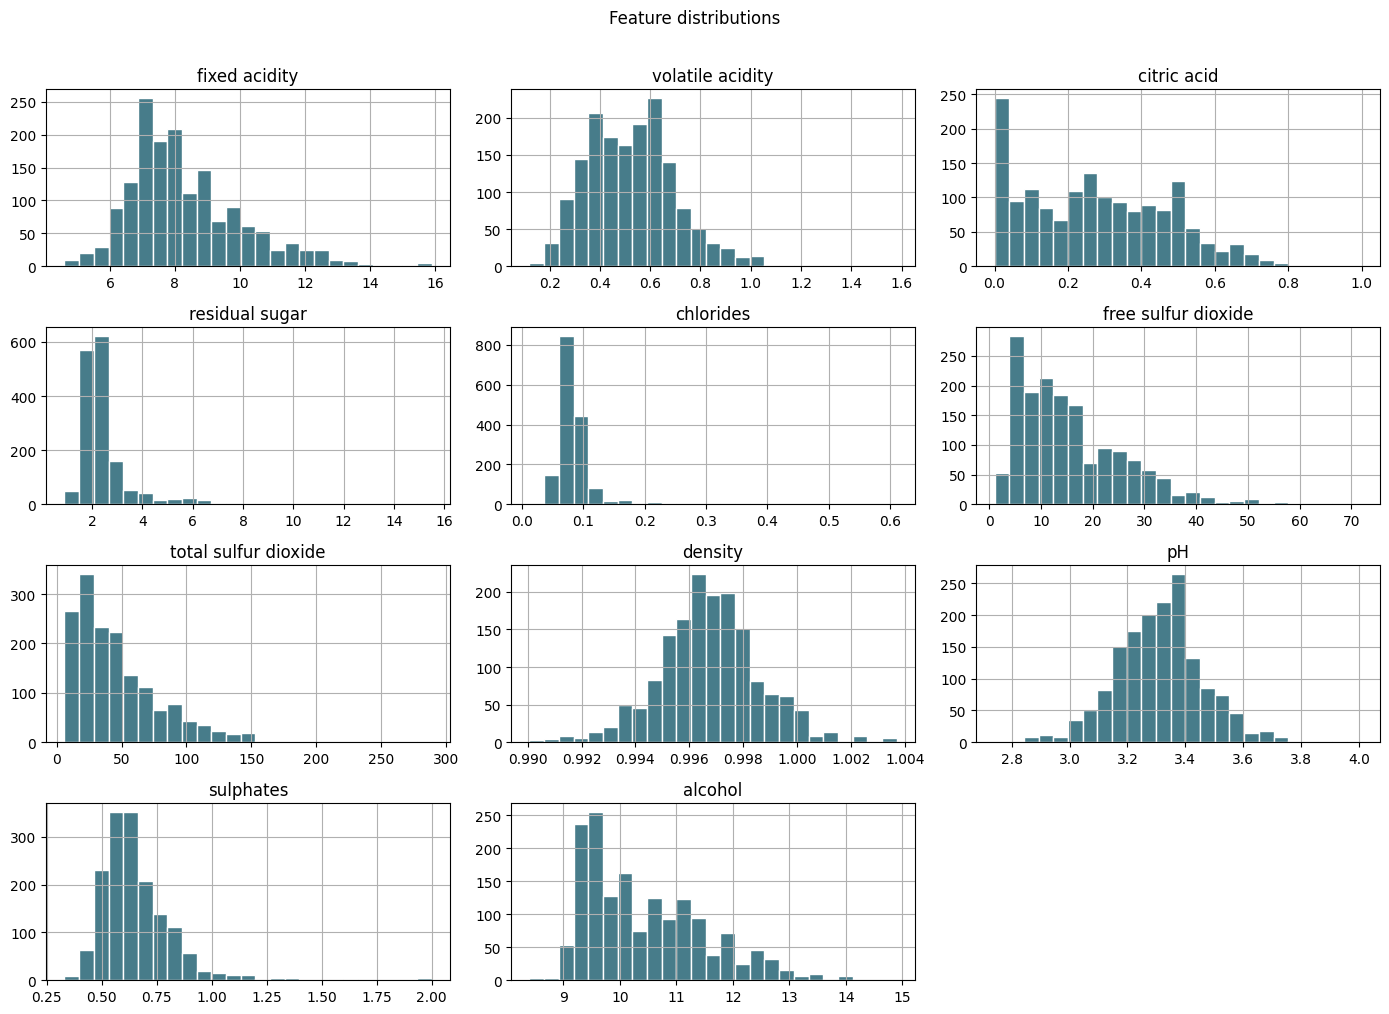

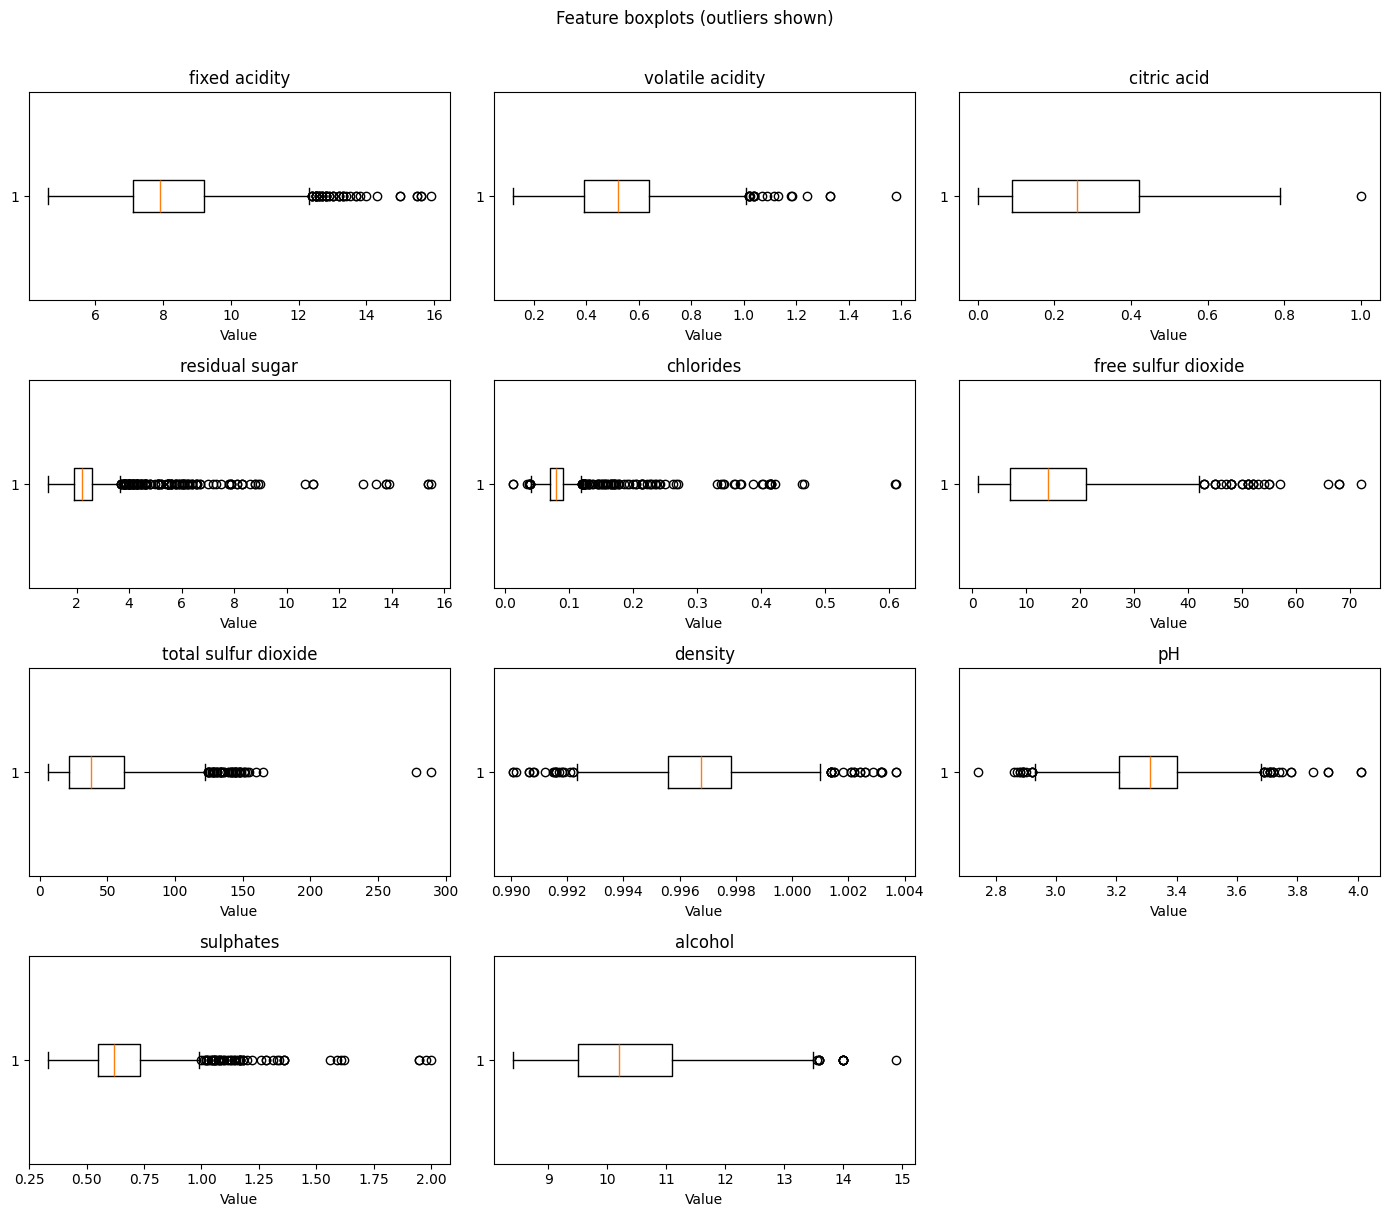

In [4]:
feature_columns = [column for column in df.columns if column not in {"quality", "good"}]
feature_data = df[feature_columns]

axes = feature_data.hist(figsize=(14, 10), bins=25, color="#477c8a", edgecolor="white")
hist_figure = axes[0, 0].figure
hist_figure.suptitle("Feature distributions", y=1.01)
hist_figure.tight_layout()
hist_figure.savefig(FIGURE_DIR / "feature_histograms.png", dpi=150, bbox_inches="tight")
display(hist_figure)
plt.close(hist_figure)

rows = (len(feature_columns) + 2) // 3
box_figure, box_axes = plt.subplots(rows, 3, figsize=(14, 3 * rows))
for axis, column in zip(box_axes.flat, feature_columns):
    axis.boxplot(feature_data[column].dropna(), vert=False, showfliers=True)
    axis.set_title(column)
    axis.set_xlabel("Value")
for axis in box_axes.flat[len(feature_columns):]:
    axis.set_visible(False)
box_figure.suptitle("Feature boxplots (outliers shown)", y=1.01)
box_figure.tight_layout()
box_figure.savefig(FIGURE_DIR / "feature_boxplots.png", dpi=150, bbox_inches="tight")
display(box_figure)
plt.close(box_figure)

## Correlation heatmap and strongest label relationships

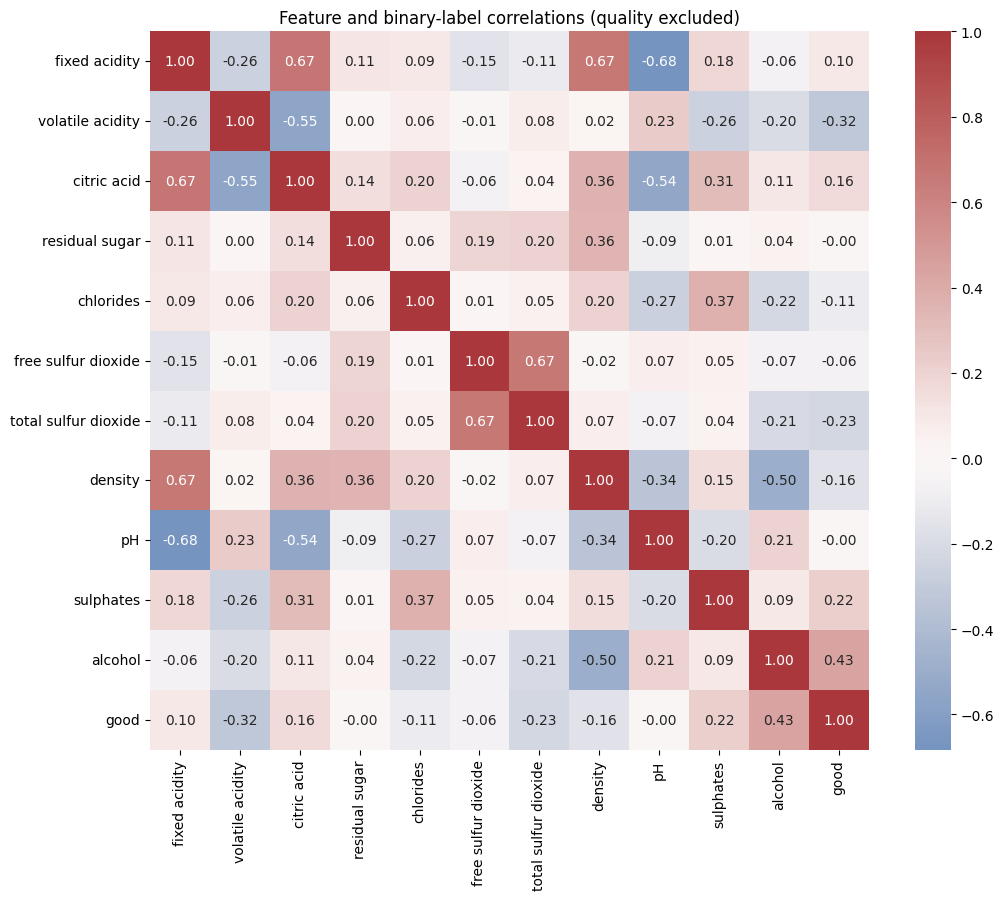

Features most correlated with the binary label (Pearson correlation):


,correlation_with_good
alcohol,0.434751
volatile acidity,-0.321441
total sulfur dioxide,-0.231963
sulphates,0.218072
citric acid,0.159129
density,-0.159110
chlorides,-0.109494
fixed acidity,0.095093
free sulfur dioxide,-0.061757
pH,-0.003264


PNG figures saved in: C:\Users\naikj\Desktop\Smart-Laboratory-Report-Generator\reports\figures


In [5]:
correlation_data = df.drop(columns="quality")
correlation_matrix = correlation_data.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(correlation_matrix, cmap="vlag", center=0, annot=True, fmt=".2f", square=True, ax=ax)
ax.set_title("Feature and binary-label correlations (quality excluded)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "correlation_heatmap.png", dpi=150, bbox_inches="tight")
display(fig)
plt.close(fig)

label_correlations = (
    correlation_matrix["good"]
    .drop(labels="good")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
print("Features most correlated with the binary label (Pearson correlation):")
display(label_correlations.head(10).rename("correlation_with_good").to_frame())
print(f"PNG figures saved in: {FIGURE_DIR}")

## Findings and decisions

- The source contains 1,599 rows and 12 columns; the derived binary label has 744 not-good rows and 855 good rows. This is a reasonably balanced baseline target, so no resampling is justified initially.
- There are 240 exact duplicate rows. Check their provenance and compare deduplicated versus retained data; do not allow duplicate copies to fall across train/test partitions, since that can inflate evaluation scores.
- `chlorides` and `residual sugar` are strongly right-skewed (skewness about 5.68 and 4.54). Inspect their boxplots; consider a transformation only if it improves validation results and is fitted within the training pipeline.
- Feature scales differ. Standardize features for logistic regression using a scaler fitted only on each training fold; random forests do not require scaling.
- Do not use `quality` as a predictor because it directly defines `good`. Keep all learned preprocessing inside the training split or cross-validation pipeline to prevent leakage.
- The strongest observed linear relationships with `good` are `alcohol` (about +0.435) and `volatile acidity` (about -0.321); correlation is descriptive, not evidence of causation.